# 📈 Machine Learning Performance Metrics Master Guide

> **Note**: In machine learning evaluation, `y_test` is the ground truth (`y_true`), and `y_pred` is the model's predictions.

This notebook covers all standard evaluation metrics across **Classification**, **Probabilistic/ROC**, **Regression**, and **Clustering**:

1. **Classification Metrics**:
   - `accuracy_score`
   - `precision_score` (with `average='binary'`, `'micro'`, `'macro'`, `'weighted'`)
   - `recall_score`
   - `f1_score`
   - `confusion_matrix` (TP, FP, TN, FN breakdown)
   - `classification_report`
2. **Probabilistic / ROC Metrics**:
   - `predict_proba`
   - `roc_curve` (False Positive Rate, True Positive Rate, Thresholds)
   - `roc_auc_score`
   - `average_precision_score` (PR-AUC)
3. **Regression Metrics**:
   - $R^2$ Score (`r2_score`)
   - Adjusted $R^2$: $1 - \frac{(1 - R^2)(n - 1)}{n - p - 1}$
   - Mean Squared Error (`mean_squared_error`) & $RMSE$
   - Mean Absolute Error (`mean_absolute_error`)
4. **Clustering Metrics**:
   - **Internal Metrics** (Unsupervised, no true labels needed):
     - `silhouette_score`
     - `calinski_harabasz_score`
     - `davies_bouldin_score`
   - **External Metrics** (Ground truth validation):
     - `adjusted_rand_score`
     - `normalized_mutual_info_score`


## 0. Setup and Data Preparation\nLoad libraries, train baseline models, and prepare `y_true`, `y_pred`, and `y_proba`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_diabetes, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.cluster import KMeans

# Styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)

# 1. Classification Data (Binary: Breast Cancer)
cancer = load_breast_cancer(as_frame=True)
X_c, y_c = cancer.data, cancer.target
X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(X_c, y_c, test_size=0.25, random_state=42, stratify=y_c)

scaler_c = StandardScaler()
X_tr_c_scaled = scaler_c.fit_transform(X_tr_c)
X_te_c_scaled = scaler_c.transform(X_te_c)

clf_bin = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_c_scaled, y_tr_c)
y_true_bin = y_te_c
y_pred_bin = clf_bin.predict(X_te_c_scaled)
y_proba_bin = clf_bin.predict_proba(X_te_c_scaled)[:, 1]

# 2. Classification Data (Multi-class: Iris)
iris = load_iris(as_frame=True)
X_iris, y_iris = iris.data, iris.target
X_tr_i, X_te_i, y_tr_i, y_te_i = train_test_split(X_iris, y_iris, test_size=0.25, random_state=42, stratify=y_iris)

scaler_i = StandardScaler()
X_tr_i_scaled = scaler_i.fit_transform(X_tr_i)
X_te_i_scaled = scaler_i.transform(X_te_i)

clf_multi = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_i_scaled, y_tr_i)
y_true_multi = y_te_i
y_pred_multi = clf_multi.predict(X_te_i_scaled)

# 3. Regression Data (Diabetes)
diabetes = load_diabetes(as_frame=True)
X_r, y_r = diabetes.data, diabetes.target
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_r, y_r, test_size=0.25, random_state=42)

reg_model = LinearRegression().fit(X_tr_r, y_tr_r)
y_true_reg = y_te_r
y_pred_reg = reg_model.predict(X_te_r)

print("✓ Datasets, test ground-truths (y_true), and predictions (y_pred) ready.")

✓ Datasets, test ground-truths (y_true), and predictions (y_pred) ready.


---
## 1. Classification Metrics

```python
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
```

- **Accuracy**: $\frac{TP + TN}{TP + TN + FP + FN}$ (Overall proportion of correct predictions).
- **Precision**: $\frac{TP}{TP + FP}$ (Quality of positive predictions; low false positive rate).
- **Recall (Sensitivity)**: $\frac{TP}{TP + FN}$ (Completeness of positive predictions; low false negative rate).
- **F1-Score**: $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ (Harmonic mean of precision and recall).


In [2]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=== 1.1 Binary Classification Metrics (Breast Cancer) ===")
acc = accuracy_score(y_true_bin, y_pred_bin)
prec = precision_score(y_true_bin, y_pred_bin, average="binary")
rec = recall_score(y_true_bin, y_pred_bin)
f1 = f1_score(y_true_bin, y_pred_bin)

print(f"Accuracy:  {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")

# Confusion Matrix and TP, TN, FP, FN calculation
cm = confusion_matrix(y_true_bin, y_pred_bin)
print("\nConfusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()
print(f"Breakdown -> True Negative (TN): {tn}, False Positive (FP): {fp}, False Negative (FN): {fn}, True Positive (TP): {tp}")

print("\n" + "="*50)
print("Classification Report:")
print(classification_report(y_true_bin, y_pred_bin, target_names=['Malignant', 'Benign']))

=== 1.1 Binary Classification Metrics (Breast Cancer) ===
Accuracy:  0.9860 (98.60%)
Precision: 0.9889
Recall:    0.9889
F1-Score:  0.9889

Confusion Matrix:
[[52  1]
 [ 1 89]]
Breakdown -> True Negative (TN): 52, False Positive (FP): 1, False Negative (FN): 1, True Positive (TP): 89

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        53
      Benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



### 1.2 Multi-Class Averaging Options: `micro`, `macro`, `weighted`
In multi-class tasks, `precision_score`, `recall_score`, and `f1_score` require specifying how to average across classes:
- **`'macro'`**: Calculates metric for each class independently and calculates unweighted mean (treats all classes equally).
- **`'weighted'`**: Calculates metric for each class and weights by class support/frequency (accounts for class imbalance).
- **`'micro'`**: Calculates globally by counting total true positives, false negatives, and false positives.


In [3]:
print("=== 1.2 Multi-Class Averaging Comparison (Iris Dataset) ===")

averaging_methods = ["micro", "macro", "weighted"]
comparison = []

for avg in averaging_methods:
    comparison.append({
        "Averaging Method": avg,
        "Precision": precision_score(y_true_multi, y_pred_multi, average=avg),
        "Recall": recall_score(y_true_multi, y_pred_multi, average=avg),
        "F1-Score": f1_score(y_true_multi, y_pred_multi, average=avg)
    })

comparison_df = pd.DataFrame(comparison)
print(comparison_df.to_string(index=False))

print("\nMulti-class Classification Report:")
print(classification_report(y_true_multi, y_pred_multi, target_names=iris.target_names))

=== 1.2 Multi-Class Averaging Comparison (Iris Dataset) ===
Averaging Method  Precision   Recall  F1-Score
           micro   0.921053 0.921053  0.921053
           macro   0.924603 0.923077  0.922963
        weighted   0.922619 0.921053  0.920936

Multi-class Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



---
## 2. Probabilistic / ROC Metrics

```python
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score

y_proba = model.predict_proba(X_test)[:, class_index]
fpr, tpr, thr = roc_curve(y_true, y_proba)
auc = roc_auc_score(y_true, y_proba)
avg_prec = average_precision_score(y_true, y_proba)
```
- **`roc_curve`**: Computes False Positive Rate ($FPR$) and True Positive Rate ($TPR$) across decision thresholds.
- **`roc_auc_score`**: Area Under the ROC Curve (1.0 = perfect model, 0.5 = random guessing).
- **`average_precision_score`**: Area Under the Precision-Recall Curve.


=== Probabilistic Performance ===
ROC-AUC Score:          0.9977
Average Precision (AP): 0.9986
Total Thresholds evaluated: 6


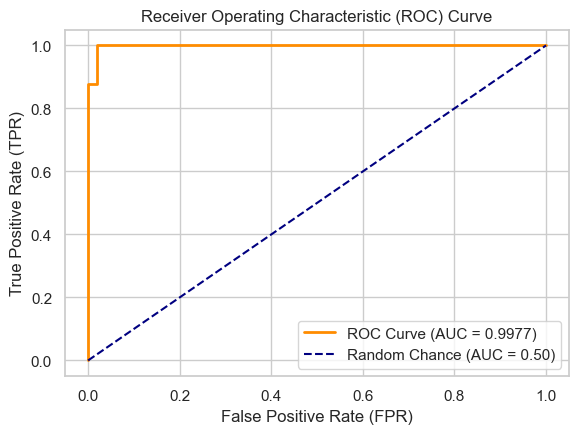

In [4]:
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score

# 1. Obtain predicted probabilities for positive class (1 = Benign)
class_index = 1
y_proba = clf_bin.predict_proba(X_te_c_scaled)[:, class_index]

# 2. Compute ROC Curve metrics
fpr, tpr, thr = roc_curve(y_true_bin, y_proba)

# 3. Compute Area Under the Curve (AUC) & Average Precision
auc = roc_auc_score(y_true_bin, y_proba)
avg_prec = average_precision_score(y_true_bin, y_proba)

print("=== Probabilistic Performance ===")
print(f"ROC-AUC Score:          {auc:.4f}")
print(f"Average Precision (AP): {avg_prec:.4f}")
print(f"Total Thresholds evaluated: {len(thr)}")

# 4. Plot ROC Curve
plt.figure(figsize=(6.5, 4.5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f"ROC Curve (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle="--", label="Random Chance (AUC = 0.50)")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.show()

---
## 3. Regression Metrics

```python
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

r2 = r2_score(y_true, y_pred)
adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
mse = mean_squared_error(y_true, y_pred)
mae = mean_absolute_error(y_true, y_pred)
```

- **$R^2$ Score**: Proportion of variance in target explained by input features (1.0 is perfect, can be negative for very poor models).
- **Adjusted $R^2$**: Penalizes addition of non-informative predictor variables:
  $$\text{Adjusted } R^2 = 1 - \frac{(1 - R^2)(n - 1)}{n - p - 1}$$
  where $n$ is sample count and $p$ is feature count.
- **$MSE$**: $\frac{1}{n}\sum (y_i - \hat{y}_i)^2$ (Penalizes larger outliers more heavily).
- **$RMSE$**: $\sqrt{MSE}$ (Interpretable in the exact original target units).
- **$MAE$**: $\frac{1}{n}\sum |y_i - \hat{y}_i|$ (Linear penalty, robust to outliers).


=== Regression Performance Metrics ===
Sample Count (n):                  111
Feature Count (p):                 10
R² Score:                          0.4849
Adjusted R² Score:                 0.4334
Mean Squared Error (MSE):          2848.31
Root Mean Squared Error (RMSE):     53.37
Mean Absolute Error (MAE):         41.55


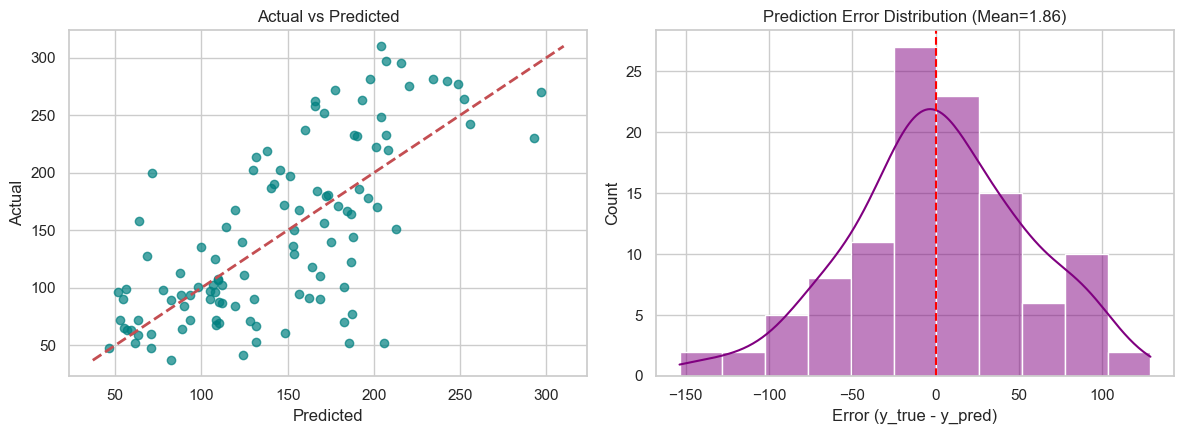

In [5]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Standard Regression Metrics
r2 = r2_score(y_true_reg, y_pred_reg)
mse = mean_squared_error(y_true_reg, y_pred_reg)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true_reg, y_pred_reg)

# 2. Adjusted R² Score Formula
n = len(y_true_reg)       # Number of observations in test set
p = X_te_r.shape[1]       # Number of predictor features
adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("=== Regression Performance Metrics ===")
print(f"Sample Count (n):                  {n}")
print(f"Feature Count (p):                 {p}")
print(f"R² Score:                          {r2:.4f}")
print(f"Adjusted R² Score:                 {adjusted_r2:.4f}")
print(f"Mean Squared Error (MSE):          {mse:.2f}")
print(f"Root Mean Squared Error (RMSE):     {rmse:.2f}")
print(f"Mean Absolute Error (MAE):         {mae:.2f}")

# Visualizing Errors
errors = y_true_reg - y_pred_reg
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(y_pred_reg, y_true_reg, alpha=0.7, color='teal')
axes[0].plot([y_true_reg.min(), y_true_reg.max()], [y_true_reg.min(), y_true_reg.max()], 'r--', lw=2)
axes[0].set_title("Actual vs Predicted")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.histplot(errors, kde=True, color='purple', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title(f"Prediction Error Distribution (Mean={errors.mean():.2f})")
axes[1].set_xlabel("Error (y_true - y_pred)")

plt.tight_layout()
plt.show()

---
## 4. Clustering Metrics

```python
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
```

### Categorization:
1. **Internal / Unsupervised Metrics** (Ground truth $y$ is NOT needed):
   - **`silhouette_score(X, labels)`**: Measures how similar an object is to its own cluster compared to other clusters. Range $[-1, +1]$, **closer to $+1$ is better**.
   - **`calinski_harabasz_score(X, labels)`**: Ratio of between-cluster dispersion to within-cluster dispersion. **Higher is better**.
   - **`davies_bouldin_score(X, labels)`**: Average similarity ratio of each cluster with its most similar cluster. **Lower is better (0 is optimal)**.

2. **External / Supervised Metrics** (Requires true labels $y_{\text{true}}$):
   - **`adjusted_rand_score(y_true, labels)`**: Measures similarity between true class assignments and cluster labels adjusted for chance. Range $[-1, 1]$, **$+1$ is identical clustering**.
   - **`normalized_mutual_info_score(y_true, labels)`**: Measures mutual information normalized between 0 and 1. **$1.0$ is perfect agreement**.


In [6]:
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

# Prepare Iris features and true species labels
X_cluster = iris.data
y_true_cluster = iris.target

# Fit K-Means with k = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
cluster_labels = kmeans.fit_predict(X_cluster)

print("=== 4.1 Internal Clustering Metrics (Unsupervised: No y_true needed) ===")
sil = silhouette_score(X_cluster, cluster_labels)
ch = calinski_harabasz_score(X_cluster, cluster_labels)
db = davies_bouldin_score(X_cluster, cluster_labels)

print(f"Silhouette Score (higher is better, max 1.0):          {sil:.4f}")
print(f"Calinski-Harabasz Score (higher is better):             {ch:.2f}")
print(f"Davies-Bouldin Score (lower is better, min 0.0):        {db:.4f}")

print("\n=== 4.2 External Clustering Metrics (Evaluated Against True Labels) ===")
ari = adjusted_rand_score(y_true_cluster, cluster_labels)
nmi = normalized_mutual_info_score(y_true_cluster, cluster_labels)

print(f"Adjusted Rand Index (ARI) (range [-1, 1], 1 is perfect): {ari:.4f}")
print(f"Normalized Mutual Info (NMI) (range [0, 1], 1 is perfect): {nmi:.4f}")

=== 4.1 Internal Clustering Metrics (Unsupervised: No y_true needed) ===
Silhouette Score (higher is better, max 1.0):          0.5512
Calinski-Harabasz Score (higher is better):             561.59
Davies-Bouldin Score (lower is better, min 0.0):        0.6660

=== 4.2 External Clustering Metrics (Evaluated Against True Labels) ===
Adjusted Rand Index (ARI) (range [-1, 1], 1 is perfect): 0.7163
Normalized Mutual Info (NMI) (range [0, 1], 1 is perfect): 0.7419


### 4.3 Finding Optimal $k$ Using Clustering Metrics
Evaluating silhouette, Calinski-Harabasz, and Davies-Bouldin scores across multiple candidate cluster counts ($k=2$ to $k=6$):


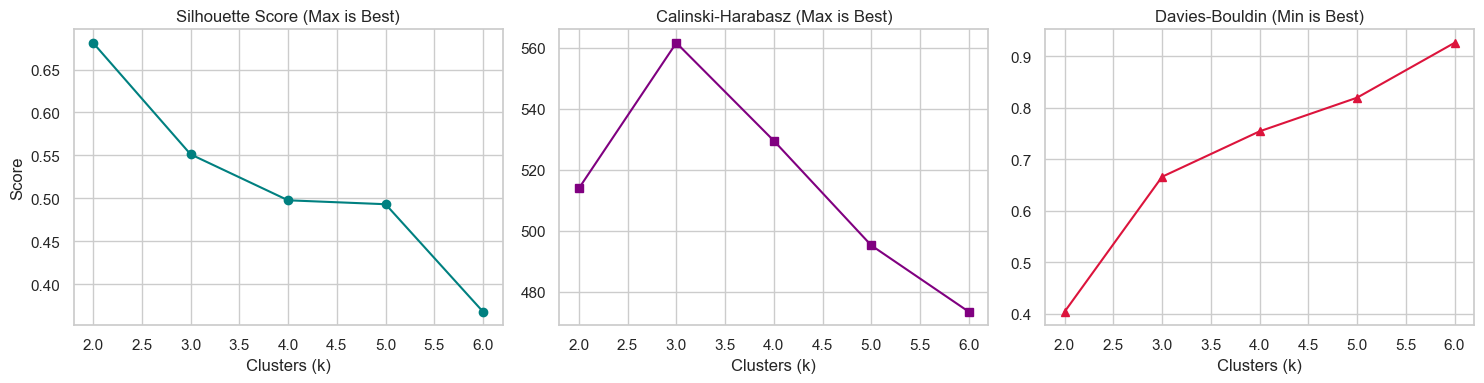

In [7]:
k_range = range(2, 7)
sil_list, ch_list, db_list = [], [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto').fit(X_cluster)
    labels_k = km.labels_
    sil_list.append(silhouette_score(X_cluster, labels_k))
    ch_list.append(calinski_harabasz_score(X_cluster, labels_k))
    db_list.append(davies_bouldin_score(X_cluster, labels_k))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(k_range, sil_list, 'o-', color='teal')
axes[0].set_title("Silhouette Score (Max is Best)")
axes[0].set_xlabel("Clusters (k)")
axes[0].set_ylabel("Score")

axes[1].plot(k_range, ch_list, 's-', color='purple')
axes[1].set_title("Calinski-Harabasz (Max is Best)")
axes[1].set_xlabel("Clusters (k)")

axes[2].plot(k_range, db_list, '^-', color='crimson')
axes[2].set_title("Davies-Bouldin (Min is Best)")
axes[2].set_xlabel("Clusters (k)")

plt.tight_layout()
plt.show()

---
## 5. 🎓 Exam Quick Reference Table

| Category | Metric Function | Key Formula / Syntax | Ideal Target | When to Use |
|---|---|---|---|---|
| **Classification** | `accuracy_score(y_true, y_pred)` | $\frac{TP + TN}{Total}$ | $1.0$ (100%) | Balanced classification datasets |
| **Classification** | `precision_score(y_true, y_pred, average=...)` | $\frac{TP}{TP + FP}$ | $1.0$ | Minimizing False Positives (e.g. Spam detection) |
| **Classification** | `recall_score(y_true, y_pred, average=...)` | $\frac{TP}{TP + FN}$ | $1.0$ | Minimizing False Negatives (e.g. Cancer detection) |
| **Classification** | `f1_score(y_true, y_pred, average=...)` | $2 \cdot \frac{P \cdot R}{P + R}$ | $1.0$ | Imbalanced classes |
| **Probabilistic** | `roc_auc_score(y_true, y_proba)` | $\int TPR \, d(FPR)$ | $1.0$ ($0.5$ is chance) | Threshold-independent ranking performance |
| **Regression** | `r2_score(y_true, y_pred)` | $1 - \frac{SS_{res}}{SS_{tot}}$ | $1.0$ | Percentage of target variance explained |
| **Regression** | `adjusted_r2` | $1 - \frac{(1 - R^2)(n - 1)}{n - p - 1}$ | $1.0$ | Multiple regression with feature penalty |
| **Regression** | `mean_squared_error(y_true, y_pred)` | $\frac{1}{n}\sum(y - \hat{y})^2$ | $0.0$ | Heavily penalizing large outlier errors |
| **Regression** | `mean_absolute_error(y_true, y_pred)` | $\frac{1}{n}\sum\|y - \hat{y}\|$ | $0.0$ | Direct average error in original units |
| **Clustering (Internal)** | `silhouette_score(X, labels)` | $\frac{b - a}{\max(a, b)}$ | $+1.0$ | Unlabeled data, checking cluster separation |
| **Clustering (Internal)** | `calinski_harabasz_score(X, labels)` | Ratio between/within dispersion | Higher | Unlabeled data, fast variance comparison |
| **Clustering (Internal)** | `davies_bouldin_score(X, labels)` | Average cluster similarity | Lower ($0.0$) | Unlabeled data, cluster compactness |
| **Clustering (External)** | `adjusted_rand_score(y_true, labels)` | Rand index adjusted for chance | $+1.0$ | When true ground-truth cluster labels exist |
| **Clustering (External)** | `normalized_mutual_info_score(y_true, labels)` | Normalized mutual information | $1.0$ | Comparing cluster output to true classes |
